# MiniGPT: Transformer & GPT from Scratch (Google Colab)

This notebook runs the whole assignment end to end on Google Colab with a GPU: setup, unit tests, overfit gate, full training, loss curves, generation, attention inspection, evaluation, ablations, and inference. The project and results are stored on Google Drive so they survive runtime disconnects.

**Before you start**
1. Push your project to a GitHub repository (see `GUIDE.md`, Step 8), or upload the zip (cell 2b).
2. Run the setup cell and authorize Google Drive when prompted.
3. Set `REPO_URL` in the setup cell to your repository.
4. Runtime -> Change runtime type -> **T4 GPU** (recommended; CPU also works but is slow).
5. Runtime -> Run all. Full training takes roughly 10-25 minutes on a T4.

If Colab disconnects, reconnect, rerun setup, and continue from the last completed section. Checkpoints and outputs are kept in `MyDrive/MiniGPT/`.


## 1. Get the code

In [8]:
import os
from pathlib import Path
from google.colab import drive

# Mount Google Drive
drive.mount("/content/drive")

# Set the project directory path
REPO_DIR = Path("/content/drive/MyDrive/transformer-gpt-assignment")
REPO_DIR.mkdir(parents=True, exist_ok=True)

# Change current working directory to the project folder
os.chdir(REPO_DIR)

print("persistent project directory:", Path.cwd())
print("results directory:", REPO_DIR / "outputs")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
persistent project directory: /content/drive/MyDrive/transformer-gpt-assignment
results directory: /content/drive/MyDrive/transformer-gpt-assignment/outputs


**2b. Alternative (no GitHub):** run this cell instead of cell 1 and upload `transformer-gpt-assignment.zip`.

In [ ]:
# from google.colab import files
# import zipfile
# up = files.upload()                       # choose the zip
# zip_path = next(iter(up))
# zipfile.ZipFile(zip_path).extractall(DRIVE_ROOT)
# os.chdir(REPO_DIR)


## 2. Install dependencies and check the GPU

In [9]:
%pip install -q -r requirements.txt
import torch
print("torch", torch.__version__, "| CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: select Runtime -> Change runtime type -> T4 GPU for faster training.")
print("project:", os.getcwd())


torch 2.11.0+cu130 | CUDA available: True
GPU: Tesla T4
project: /content/drive/MyDrive/transformer-gpt-assignment


## 3. Unit tests (architecture and causal-mask checks)

In [10]:
!mkdir -p outputs/logs
!python -m pytest -q | tee outputs/logs/pytest_colab.txt

................                                                         [100%]
16 passed in 4.60s


## 4. Overfit gate (Milestone 4): the loss must fall substantially on a tiny batch

In [11]:
!python -m src.train --overfit --run-name overfit --device auto

[overfit] device=cuda parameters=806,656 vocab=52 train_windows=21 val_windows=2
step      1 | lr 3.00e-03 | train 3.9944 | val 3.5198 |     0.3s
step    250 | lr 3.00e-03 | train 0.6503 | val 0.0014 |     5.3s
step    300 | lr 3.00e-03 | train 0.0014 | val 0.0014 |     6.6s
done in 7.2s | params 806,656 | best val 0.0014
logs: outputs/logs/overfit  checkpoint: checkpoints/overfit_best.pt


## 5. Full MiniGPT training (Milestone 5)

In [12]:
!python -m src.train --config configs/tiny_gpt.yaml --run-name mini_gpt --device auto

[mini_gpt] device=cuda parameters=809,984 vocab=65 train_windows=7842 val_windows=871
step      1 | lr 5.00e-06 | train 4.2195 | val 4.2164 |     0.6s
    sample: 'ROMEO:CkMBbzA$3:XaSvgO-33SM:d?gLTa\nhX:YVXJthXMNuwqcPMWG.tbaF dXl!DZaLeWFwccHPgRWk,fDEZnYzxzCImmX\nYoR'
step    250 | lr 1.00e-03 | train 3.2306 | val 2.5968 |     5.4s
    sample: 'ROMEO:\nThidif Cocrdat auerd miters opat athele mat my thof raeous cere ngrr hime d t heple meth ht,\n'
step    500 | lr 9.91e-04 | train 2.4549 | val 2.2830 |    10.7s
    sample: "ROMEO:\nSay thes Mest fodr win wour toll you oou nor's\nFe thiy the and set aur thims thene chat yok.\n"
step    750 | lr 9.71e-04 | train 2.2142 | val 2.1075 |    15.3s
    sample: 'ROMEO:\nWhe the much for the my dise a is; me skire.\n\nCALUT:\nWos mande whe not for tull and we thath '
step   1000 | lr 9.40e-04 | train 2.0415 | val 1.9824 |    20.1s
    sample: "ROMEO:\nWhy I my sopler'd sthe prike heer,\nThe sleater so in of thou the seem.\n\nDUKE VINCARET:\nWhos! 

## 6. Loss curves (Figure 6)

saved outputs/figures/fig06_loss_curves.png


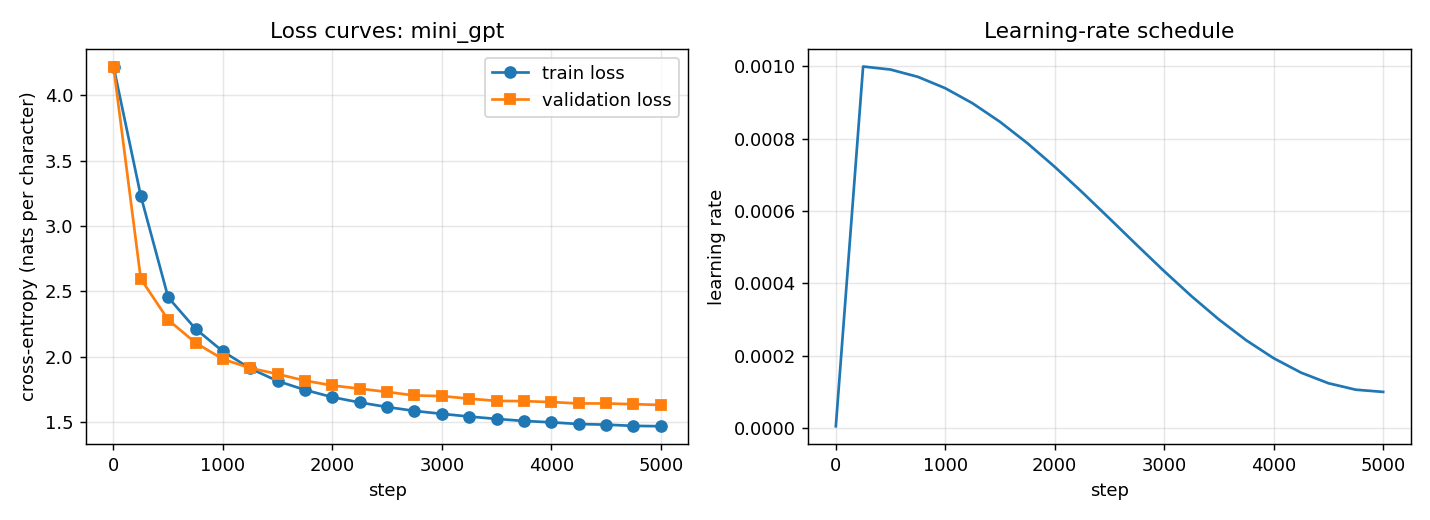

{
  "run": "mini_gpt",
  "device": "cuda",
  "hardware": "Tesla T4",
  "parameters": 809984,
  "steps": 5000,
  "context_length": 128,
  "n_layers": 4,
  "n_heads": 4,
  "d_model": 128,
  "pos_encoding": "sinusoidal",
  "first_train_loss": 4.219481468200684,
  "final_train_loss": 1.4695858459472657,
  "final_val_loss": 1.632452483688082,
  "best_val_loss": 1.632452483688082,
  "train_time_s": 100.6,
  "tokens_per_sec": 203493.1,
  "peak_mem_mb": 209.1
}

In [13]:
!python -m experiments.plot_curves --run mini_gpt
from IPython.display import Image, display
display(Image("outputs/figures/fig06_loss_curves.png"))
!cat outputs/logs/mini_gpt/summary.json


## 7. Generate samples from fixed prompts (Figure 8)

In [14]:
from pathlib import Path
from src.generate import load_model, generate_text
from src.utils import count_parameters, get_device

checkpoint = Path("checkpoints/mini_gpt_best.pt")
if not checkpoint.exists():
    raise FileNotFoundError(f"Missing {checkpoint}. Run training first or restore the Drive project.")
device = get_device("auto")
model, tok = load_model(str(checkpoint), device)
print(f"Loaded {checkpoint} on {device}; parameters: {count_parameters(model):,}")
for prompt in ["ROMEO:", "First Citizen:\n", "To be, or not to be", "KING HENRY:", "The future of"]:
    print("=" * 70)
    print(generate_text(model, tok, prompt, max_new_tokens=120, temperature=0.8, top_k=40, seed=0, device=device))


Loaded checkpoints/mini_gpt_best.pt on cuda; parameters: 809,984
ROMEO:
Say he not like more absent you caith.

Nurse:
And we good my lord:
And so better so thus servic lose this the shall be
First Citizen:
Ay, and not like more abstuing me?

ABRAHAM:
When you he shall not confers, by the sons.

MENENIUS:
This impropts save t
To be, or not to be day things,
That time but thy mockingded blood, and they brow
The conserves for ster the great of the faithful sheaves

KING HENRY:
Say me not like more absom, you caith.

Nurse:
And we good my lord:
Ay thou what desired the brother of impropts.

Firs
The future of your hinder beat time.

CORIOLANUS:
But in the mean;
And by we three in the father! it unto grace,
To be my Lord Angelo


## 8. Hand-calculation figures, mask, positional encoding, shape trace, model summary (Figures 2-5)

Forward-pass shape trace (batch=2, T=16):
[model] token ids (2, 16) -> embeddings (2, 16, 128)
  [block] input (2, 16, 128)
    [MHA] input x            (2, 16, 128)  (B, T, D)
    [MHA] q/k/v after split  (2, 4, 16, 32)  (B, H, T, d_head)
    [MHA] attention weights  (2, 4, 16, 16)  (B, H, T_query, T_key)
    [MHA] head outputs       (2, 4, 16, 32)  -> merged (2, 16, 128)
    [MHA] after out_proj     (2, 16, 128)
  [block] output (2, 16, 128)
  [block] input (2, 16, 128)
    [MHA] input x            (2, 16, 128)  (B, T, D)
    [MHA] q/k/v after split  (2, 4, 16, 32)  (B, H, T, d_head)
    [MHA] attention weights  (2, 4, 16, 16)  (B, H, T_query, T_key)
    [MHA] head outputs       (2, 4, 16, 32)  -> merged (2, 16, 128)
    [MHA] after out_proj     (2, 16, 128)
  [block] output (2, 16, 128)
  [block] input (2, 16, 128)
    [MHA] input x            (2, 16, 128)  (B, T, D)
    [MHA] q/k/v after split  (2, 4, 16, 32)  (B, H, T, d_head)
    [MHA] attention weights  (2, 4, 16, 16)  (B, H, T_

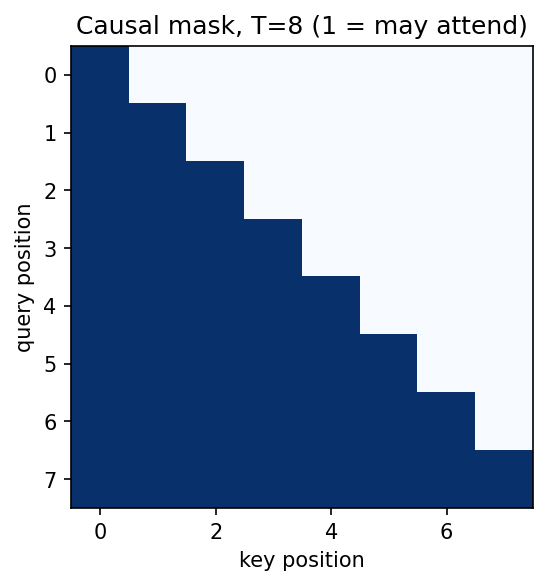

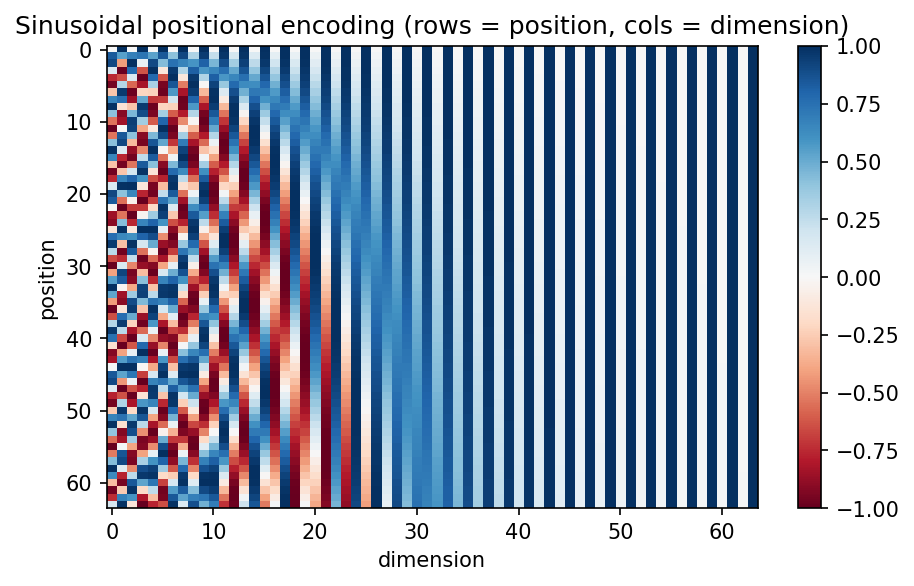

In [15]:
!python -m experiments.static_figures
from IPython.display import Image, display
display(Image("outputs/figures/fig02_causal_mask.png"))
display(Image("outputs/figures/fig04_positional_encoding.png"))


## 9. Attention inspection of the trained model (Figure 7)

saved outputs/figures/fig07_attention_trained.png
Prompt tokens: ['R', 'O', 'M', 'E', 'O', ':']
final layer head 0, last query attends most to: pos 5 : (0.25), pos 0 R (0.25), pos 4 O (0.25)
final layer head 1, last query attends most to: pos 0 R (0.50), pos 4 O (0.26), pos 2 M (0.08)
final layer head 2, last query attends most to: pos 5 : (0.68), pos 1 O (0.08), pos 4 O (0.08)
final layer head 3, last query attends most to: pos 5 : (0.29), pos 4 O (0.20), pos 3 E (0.18)


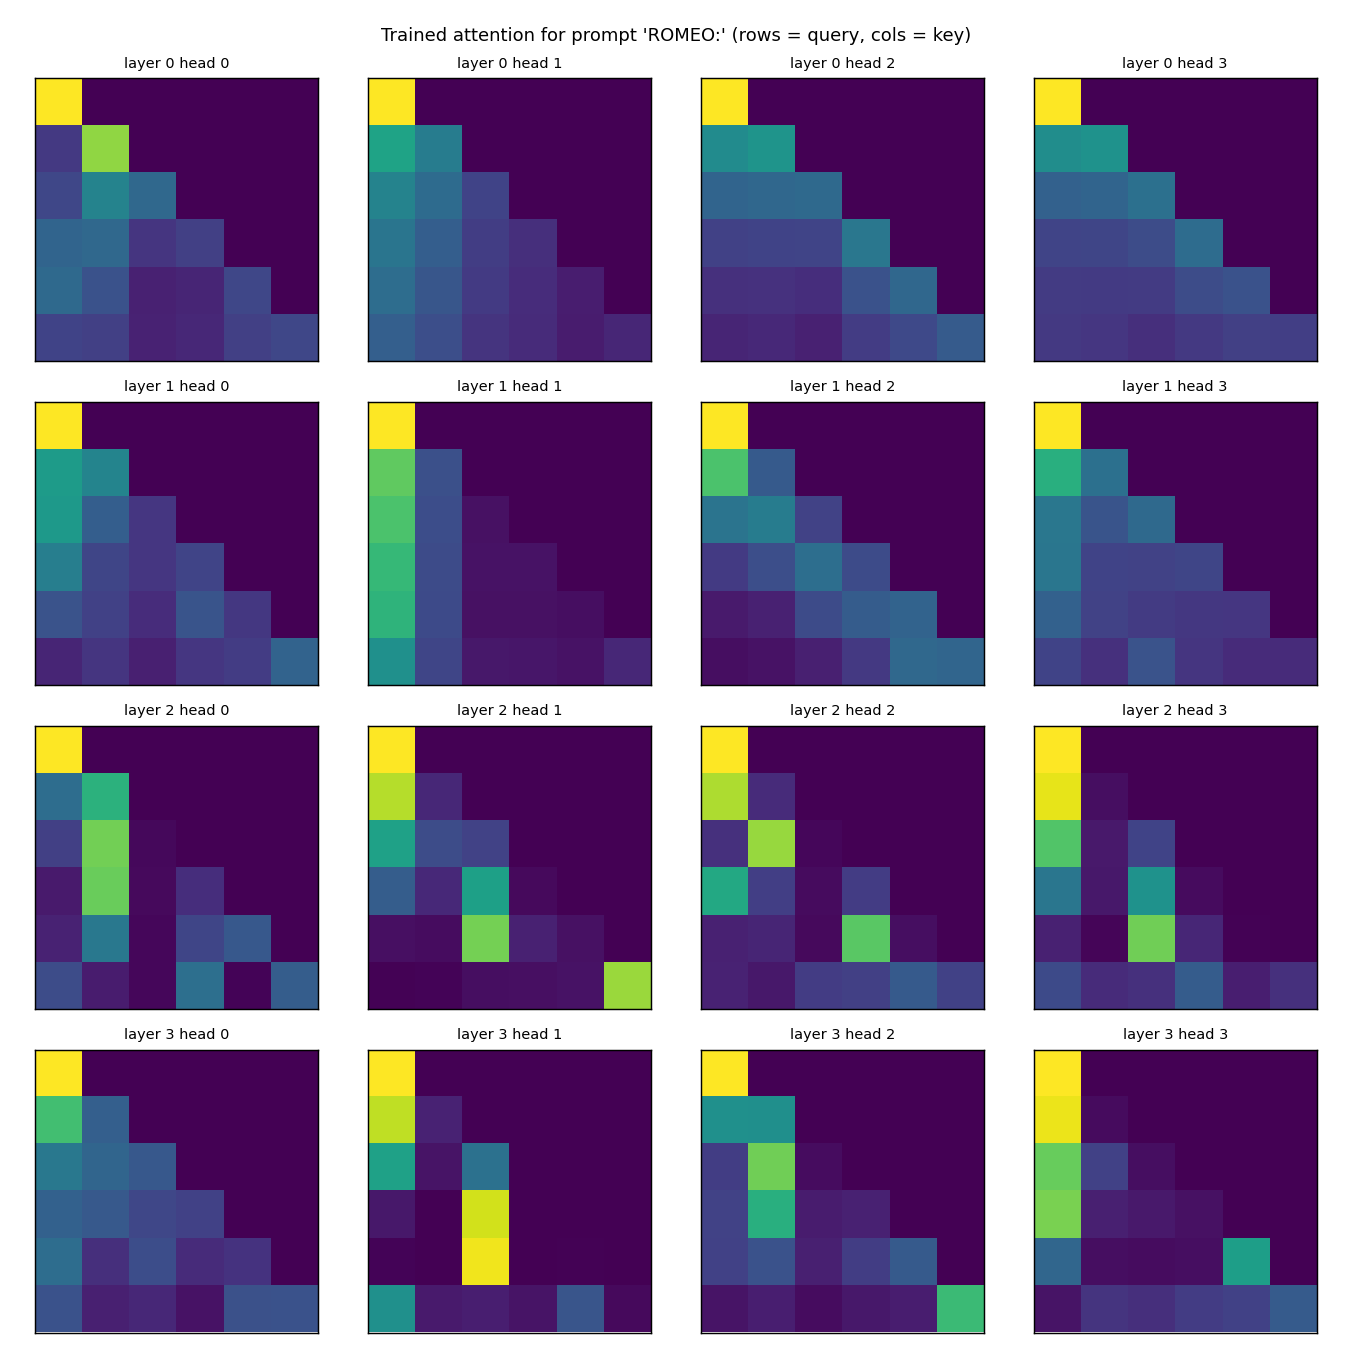

In [16]:
!python -m experiments.attention_visualization --prompt "ROMEO:"
from IPython.display import Image, display
display(Image("outputs/figures/fig07_attention_trained.png"))


## 10. Evaluation: perplexity, causality check, samples

In [17]:
!python -m experiments.evaluate
!head -n 30 outputs/samples/eval_samples.md


validation loss 1.6325 | perplexity 5.116 | causality PASS
samples written to outputs/samples/eval_samples.md
# Evaluation samples

Checkpoint: `checkpoints/mini_gpt_best.pt`  | validation loss 1.6325 | perplexity 5.116
Causality check (future tokens cannot affect past logits): **PASS**

## Prompt 'ROMEO:'

**Greedy:**
```
ROMEO:
The sent of the senators of the senators
That the senators of the son of the son,
And the senators of the senators of the stands
To the sent of the stander of the stander of the senators
That I will 
```

**Temperature 0.8 (seed 0):**
```
ROMEO:
Say he not like more absent you caith.

Nurse:
And we good my lord:
And so better so thus servic lose this the shall be come to
Ender a duile, and be very great we know and to purgets
That be it be w
```

## Prompt 'First Citizen:\n'


## 11. Ablation studies (Figure 9). Slow: about 12 short training runs. Lower `--steps` for a quick pass.

In [18]:
!python -m experiments.ablation --steps 1500



>>> --config configs/tiny_gpt.yaml --run-name abl_depth_2 --set model.n_layers=2 train.max_steps=1500 train.warmup_steps=150 train.eval_interval=250
[abl_depth_2] device=cuda parameters=413,440 vocab=65 train_windows=7842 val_windows=871
step      1 | lr 6.67e-06 | train 4.2120 | val 4.2142 |     0.5s
    sample: 'ROMEO:,OLlT,ebtK\nb:!PWCkMBbzA$3:XaSvgO-3qjM:d?gLTa\nhX:YVXbthXNNuwqcP,xv.tbaF dXlaDZaAeWFw3cHPmRWk,fD'
step    250 | lr 9.88e-04 | train 3.1903 | val 2.5869 |     3.4s
    sample: 'ROMEO:\nPETHFo fend me ba the thean geerin kithetoofr as was hene g,\nBhed IRGERCICIULNowet ore hat f '
step    500 | lr 8.60e-04 | train 2.4650 | val 2.3137 |     6.7s
    sample: 'ROMEO:\nBit su tha pe oet ho my my ou hat, an thyoue pous.\n\n\nJUWIE:\nThanmy hendely arer spowe cind le'
step    750 | lr 6.29e-04 | train 2.2749 | val 2.1866 |     9.3s
    sample: 'ROMEO:\nWhem wal wee werllBy lord the athe bucttinrs.\n\nCOLALING HARDWE:\nI that to cangh thealt his no'
step   1000 | lr 3.73e-04 | 

## 12. Inference CLI (Figure 10 evidence)

In [19]:
from pathlib import Path
checkpoint = Path("checkpoints/mini_gpt_best.pt")
if not checkpoint.exists():
    raise FileNotFoundError(f"Missing {checkpoint}. Run the training cell first.")
!python -m src.generate --ckpt checkpoints/mini_gpt_best.pt --prompt "The future of" --max-new-tokens 80 --temperature 0.8 --device auto


Prompt: The future of
Generated: The future of thy body will not curse
Of the listle, the queen of his glorious,
'Twas to rest
model parameters: 809,984
context length: 128
temperature: 0.8


## 13. Bundle all results for download

In [20]:
from pathlib import Path
import zipfile

bundle_path = Path("/content/drive/MyDrive/transformer-gpt-assignment/results_bundle.zip")
with zipfile.ZipFile(bundle_path, "w", zipfile.ZIP_DEFLATED) as bundle:
    for path in Path("outputs").rglob("*"):
        if path.is_file():
            bundle.write(path, path.as_posix())
    checkpoint = Path("checkpoints/mini_gpt_best.pt")
    if checkpoint.exists():
        bundle.write(checkpoint, checkpoint.as_posix())
print("Saved results:", bundle_path)
print("Checkpoint:", Path("checkpoints/mini_gpt_best.pt").resolve())
try:
    from google.colab import files
    files.download(str(bundle_path))
except ImportError:
    print("Not on Colab: results are saved in Google Drive.")


Saved results: /content/drive/MyDrive/transformer-gpt-assignment/results_bundle.zip
Checkpoint: /content/drive/MyDrive/transformer-gpt-assignment/checkpoints/mini_gpt_best.pt


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>